# Span Overlap Visualization

Visualize how verbatim spans of a reference text overlap across corpus documents, using the matches produced by `curation.retrieval` (infini_gram_mini or BM25 backends).

## Why these visualizations?

Surveying the dataset-search and memorization-attribution literature, the consistently useful visual idioms are:

1. **Per-character coverage heatmap over the reference** — for each char position, the color encodes the length of the longest verbatim span covering that position. Used in *OLMoTrace* (Liu et al., 2024) and the memorization work of Carlini et al. to show at a glance which parts of a text are "well-remembered".
2. **Span lanes (IGV/bioinformatics-style coverage tracks)** — each span is a horizontal bar at its reference position; lanes stack non-overlapping spans, producing a pileup view. Borrowed from genome-browser read-pile displays (Robinson et al., IGV).
3. **Inline HTML rendering with highlighted spans** — the reference text itself with matched regions color-coded, linking to doc metadata on hover. Used by *OLMoTrace* and *Infini-gram* demos for qualitative inspection.
4. **Source-document / category distribution** — bar or treemap of where spans come from (which Dolma subset, which doc). Useful to see whether matches are dominated by one source or spread across many.
5. **Span-length distribution (CDF)** — how verbatim is the match? Long tail of short spans vs a few long ones tells you memorization vs incidental n-gram overlap.
6. **Count × length scatter** — each span as (span_length, corpus_count) — identifies spans that are both long *and* frequent (strong memorization signal) vs long-but-rare (possibly one-source copy).

This notebook implements 1–6 for a single item and leaves simple entry points to iterate across the dataset.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

MATCHES_PATH = Path(
    "/lfs/skampere2/0/animjha/CleanSlate/curation/outputs/"
    "infini_gram_mini_cleanslate_dolma3_10B/2aabbf5ac35c/matches.parquet"
)

df = pq.read_table(MATCHES_PATH).to_pandas()
print(f"{len(df):,} rows across {df['content_id'].nunique():,} items")
df.head(3)

287,485 rows across 4,638 items


,content_id,content_title,reference_target,retrieval_method,corpus_name,doc_id,doc_source,doc_category,unit_id,unit_char_start,unit_char_end,rank,score,retrieved_text,metadata
0,000236177e84c7d3d17151350ff5a24b2293eb94,They Want EFX,"Bum stiggedy bum stiggedy bum, hon, I got the ...",infini_gram_mini,dolma3_10B,4602648,nemotron-synth-qa/shard_00000119.jsonl.zst,nemotron-synth-qa,000236177e84c7d3d17151350ff5a24b2293eb94_span_...,3082,3118,1,36.0,hold it in place while he sits on it like a d...,"{""span_text"": ""pokey and you turn yourself aro..."
1,000236177e84c7d3d17151350ff5a24b2293eb94,They Want EFX,"Bum stiggedy bum stiggedy bum, hon, I got the ...",infini_gram_mini,dolma3_10B,514189,common_crawl-high-quality_20_entertainment/sha...,common_crawl-high-quality_20_entertainment,000236177e84c7d3d17151350ff5a24b2293eb94_span_...,1531,1563,2,32.0,"of who he was up against. (See, wasn't that fu...","{""span_text"": ""s everybody always picking on m..."
2,000236177e84c7d3d17151350ff5a24b2293eb94,They Want EFX,"Bum stiggedy bum stiggedy bum, hon, I got the ...",infini_gram_mini,dolma3_10B,90670,common_crawl-high-quality_19_entertainment/sha...,common_crawl-high-quality_19_entertainment,000236177e84c7d3d17151350ff5a24b2293eb94_span_...,3066,3096,3,30.0,"se/promotion.\n\nDaya: “I love you, Jon, but y...","{""span_text"": ""ou do the hokey pokey and you ""..."


In [8]:
def parse_metadata(row: pd.Series) -> dict:
    m = row.get("metadata")
    if isinstance(m, str) and m:
        return json.loads(m)
    return {}


def item_frame(df: pd.DataFrame, content_id: str) -> pd.DataFrame:
    """Subset to one item, parse metadata into columns, sort by rank."""
    sub = df[df["content_id"] == content_id].copy().sort_values("rank")
    meta = sub.apply(parse_metadata, axis=1)
    sub["span_text"] = meta.apply(lambda m: m.get("span_text", ""))
    sub["corpus_count"] = meta.apply(lambda m: m.get("corpus_count", 0))
    sub["coverage"] = meta.apply(lambda m: m.get("coverage", float("nan")))
    sub["total_spans"] = meta.apply(lambda m: m.get("total_spans", len(sub)))
    sub["span_len"] = sub["unit_char_end"] - sub["unit_char_start"]
    return sub


# Iris by Goo Goo Dolls — good demo case (95% coverage, 65 spans)
# CONTENT_ID = "9bd7dd3ff9165c9ecce1313aed6a2915fd8f43ab"
CONTENT_ID = "b9bb555ab4913dfeaafb409555e8f543f5180fc6" # never gonna give you up
item = item_frame(df, CONTENT_ID)
print(f"{item['content_title'].iloc[0]!r}: {len(item)} spans, coverage={item['coverage'].iloc[0]:.1%}")
print(f"reference length: {len(item['reference_target'].iloc[0])} chars")

'Never Gonna Give You Up': 38 spans, coverage=98.0%
reference length: 1839 chars


## 1. Per-character coverage heatmap

For each char position `i`, compute `max(span_len)` over all spans covering `i`. Color-encode on a 1D strip. This shows which regions of the reference have strong verbatim evidence vs weak/no evidence.

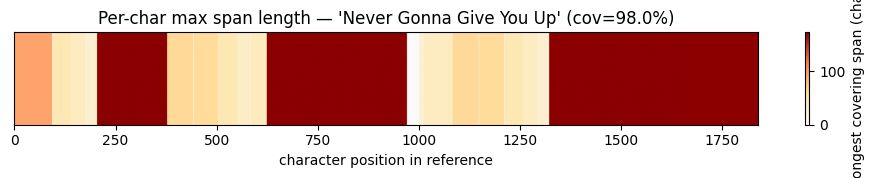

In [9]:
def coverage_vector(item: pd.DataFrame, n: int | None = None) -> np.ndarray:
    """Per-character: max span length covering that position (0 if no span)."""
    if n is None:
        n = len(item["reference_target"].iloc[0])
    v = np.zeros(n, dtype=np.int32)
    for _, r in item.iterrows():
        s, e = int(r["unit_char_start"]), int(r["unit_char_end"])
        sl = e - s
        v[s:e] = np.maximum(v[s:e], sl)
    return v


def plot_coverage_heatmap(item: pd.DataFrame, ax=None):
    v = coverage_vector(item)
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 1.2))
    cmap = LinearSegmentedColormap.from_list(
        "cov", ["#fafafa", "#ffe4a0", "#ff7f50", "#8b0000"], N=256
    )
    im = ax.imshow(v[None, :], aspect="auto", cmap=cmap, vmin=0, vmax=max(1, v.max()))
    ax.set_yticks([])
    ax.set_xlabel("character position in reference")
    ax.set_title(
        f"Per-char max span length — {item['content_title'].iloc[0]!r} "
        f"(cov={item['coverage'].iloc[0]:.1%})"
    )
    plt.colorbar(im, ax=ax, label="longest covering span (chars)")
    return ax


plot_coverage_heatmap(item)
plt.show()

## 2. Span lanes (IGV-style pileup)

Each span is a horizontal bar at its start/end. Greedy lane assignment packs non-overlapping spans vertically so you see the pileup structure.

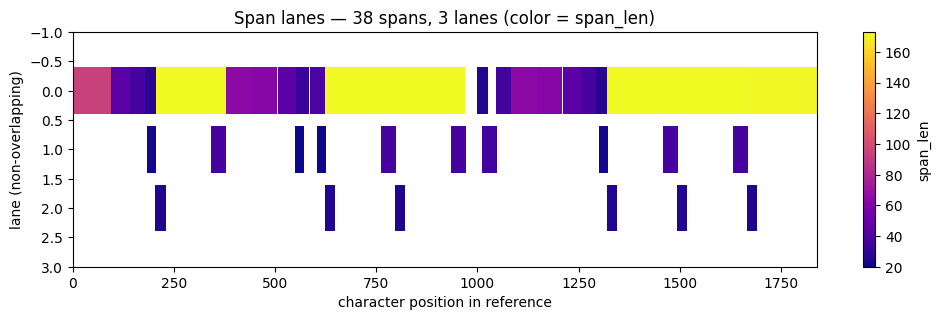

In [10]:
def assign_lanes(spans: list[tuple[int, int]]) -> list[int]:
    """Return lane index per span such that same-lane spans don't overlap.
    Spans come in as (start, end); process in start-ascending order."""
    order = sorted(range(len(spans)), key=lambda i: (spans[i][0], -(spans[i][1] - spans[i][0])))
    lanes: list[int] = [0] * len(spans)
    lane_ends: list[int] = []  # end position of the last span placed in each lane
    for idx in order:
        s, e = spans[idx]
        placed = False
        for lane, lane_end in enumerate(lane_ends):
            if s >= lane_end:
                lanes[idx] = lane
                lane_ends[lane] = e
                placed = True
                break
        if not placed:
            lanes[idx] = len(lane_ends)
            lane_ends.append(e)
    return lanes


def plot_span_lanes(item: pd.DataFrame, color_by: str = "span_len"):
    spans = list(zip(item["unit_char_start"].astype(int), item["unit_char_end"].astype(int)))
    lanes = assign_lanes(spans)
    n_lanes = max(lanes) + 1 if lanes else 1

    fig, ax = plt.subplots(figsize=(12, 0.35 * n_lanes + 2))
    vals = item[color_by].astype(float).to_numpy()
    vmin, vmax = float(vals.min()), float(vals.max())
    cmap = plt.get_cmap("plasma")
    norm = plt.Normalize(vmin=vmin, vmax=max(vmax, vmin + 1e-9))

    for (s, e), lane, v in zip(spans, lanes, vals):
        rect = Rectangle((s, lane - 0.4), e - s, 0.8, facecolor=cmap(norm(v)), edgecolor="none")
        ax.add_patch(rect)

    n_ref = len(item["reference_target"].iloc[0])
    ax.set_xlim(0, n_ref)
    ax.set_ylim(-1, n_lanes)
    ax.invert_yaxis()
    ax.set_ylabel("lane (non-overlapping)")
    ax.set_xlabel("character position in reference")
    ax.set_title(f"Span lanes — {len(spans)} spans, {n_lanes} lanes (color = {color_by})")
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    plt.colorbar(sm, ax=ax, label=color_by)
    return ax


plot_span_lanes(item, color_by="span_len")
plt.show()

## 3. Inline HTML rendering

Render the reference text with matched positions highlighted. Intensity encodes the longest span covering each char, so overlapping regions darken.

In [11]:
def render_inline_html(item: pd.DataFrame) -> HTML:
    ref = item["reference_target"].iloc[0]
    v = coverage_vector(item, n=len(ref))
    vmax = max(1, int(v.max()))

    def css(val: int) -> str:
        if val == 0:
            return ""
        # log-scale intensity so tiny spans aren't invisible, long ones don't saturate
        alpha = 0.15 + 0.75 * (np.log1p(val) / np.log1p(vmax))
        return f"background: rgba(255, 80, 0, {alpha:.2f});"

    # group consecutive chars with same coverage bucket into spans for compactness
    parts = []
    buf = []
    buf_val = v[0] if len(v) else 0
    for i, (ch, val) in enumerate(zip(ref, v)):
        if val != buf_val:
            chunk = "".join(buf).replace("<", "&lt;").replace("\n", "<br>")
            parts.append(f'<span style="{css(buf_val)}" title="max-span={buf_val}">{chunk}</span>')
            buf = []
            buf_val = val
        buf.append(ch)
    if buf:
        chunk = "".join(buf).replace("<", "&lt;").replace("\n", "<br>")
        parts.append(f'<span style="{css(buf_val)}" title="max-span={buf_val}">{chunk}</span>')

    html = (
        f'<div style="font-family: monospace; font-size: 13px; line-height: 1.6; '
        f'padding: 12px; border: 1px solid #ddd; max-width: 900px; white-space: pre-wrap;">'
        + "".join(parts)
        + "</div>"
    )
    return HTML(html)


display(render_inline_html(item))

## 3b. Highlighted spans with per-span match counts

Render the reference text with each matched span outlined. Every span shows two numbers:

- **n_corpus** — `corpus_count` from metadata: how many times this exact substring occurs across the whole corpus (global n-gram frequency).
- **n_docs** — how many distinct retrieved documents in this matches file contain the span (a lower bound — retrieval is top-k capped).

Color intensity encodes `log(n_corpus)` so spans that are both long *and* frequent stand out. Hovering shows the full span text + both counts.

In [12]:
def unique_spans(item: pd.DataFrame) -> pd.DataFrame:
    """Collapse matches → one row per distinct (start, end) span.

    For each span: corpus_count (from metadata, max over rows in case of drift),
    n_docs (# unique doc_ids retrieved), and the span_text.
    """
    g = (
        item.groupby(["unit_char_start", "unit_char_end"], as_index=False)
        .agg(
            corpus_count=("corpus_count", "max"),
            n_docs=("doc_id", "nunique"),
            span_text=("span_text", "first"),
            best_rank=("rank", "min"),
        )
        .sort_values("unit_char_start")
        .reset_index(drop=True)
    )
    g["span_len"] = g["unit_char_end"] - g["unit_char_start"]
    return g


def render_spans_with_counts(item: pd.DataFrame, max_rows_in_table: int = 30) -> HTML:
    """Inline text w/ each span colored by log(corpus_count), count badges after each span,
    plus a ranked table beneath."""
    ref = item["reference_target"].iloc[0]
    spans = unique_spans(item)

    # Per-char attribution: map each char to the span (index into `spans`) with the highest
    # corpus_count covering it. Ties broken by longer span.
    n = len(ref)
    best_idx = np.full(n, -1, dtype=np.int32)
    best_score = np.full(n, -1.0, dtype=np.float64)
    for idx, r in spans.iterrows():
        s, e = int(r["unit_char_start"]), int(r["unit_char_end"])
        score = float(r["corpus_count"]) * 1000 + (e - s)  # count dominates, length tiebreak
        region = best_score[s:e] < score
        best_idx[s:e][region] = idx
        best_score[s:e][region] = score

    cmax = max(1, int(spans["corpus_count"].max()))

    def color(idx: int) -> str:
        if idx < 0:
            return ""
        c = int(spans.loc[idx, "corpus_count"])
        alpha = 0.15 + 0.75 * (np.log1p(c) / np.log1p(cmax))
        return f"background: rgba(255, 80, 0, {alpha:.2f});"

    # Walk the reference char-by-char; open a span when best_idx changes.
    parts: list[str] = []
    cursor = 0
    while cursor < n:
        idx = int(best_idx[cursor])
        j = cursor
        while j < n and int(best_idx[j]) == idx:
            j += 1
        chunk = ref[cursor:j].replace("<", "&lt;").replace("\n", "<br>")
        if idx < 0:
            parts.append(f'<span>{chunk}</span>')
        else:
            r = spans.loc[idx]
            tip = (
                f"span_text={r['span_text']!r} | n_corpus={int(r['corpus_count'])} | "
                f"n_docs={int(r['n_docs'])} | len={int(r['span_len'])}"
            ).replace('"', "&quot;")
            parts.append(f'<span style="{color(idx)}" title="{tip}">{chunk}</span>')
            # If this chunk ends at the true span boundary, append an inline count badge.
            if j == int(r["unit_char_end"]):
                parts.append(
                    f'<sup style="background:#333; color:#fff; padding:1px 4px; '
                    f'margin:0 2px; border-radius:3px; font-size:10px;" '
                    f'title="{tip}">{int(r["corpus_count"])}</sup>'
                )
        cursor = j

    html_text = (
        '<div style="font-family: monospace; font-size: 13px; line-height: 1.9; '
        'padding: 12px; border: 1px solid #ddd; max-width: 900px; white-space: pre-wrap;">'
        + "".join(parts)
        + "</div>"
    )

    # Ranked table
    table = spans.sort_values("corpus_count", ascending=False).head(max_rows_in_table)
    rows = []
    for _, r in table.iterrows():
        txt = str(r["span_text"]).replace("<", "&lt;")
        if len(txt) > 120:
            txt = txt[:117] + "…"
        rows.append(
            f"<tr><td style='padding:3px 8px;'>{int(r['unit_char_start'])}–{int(r['unit_char_end'])}</td>"
            f"<td style='padding:3px 8px;'>{int(r['span_len'])}</td>"
            f"<td style='padding:3px 8px; text-align:right;'><b>{int(r['corpus_count'])}</b></td>"
            f"<td style='padding:3px 8px; text-align:right;'>{int(r['n_docs'])}</td>"
            f"<td style='padding:3px 8px; font-family:monospace;'>{txt}</td></tr>"
        )
    html_table = (
        '<table style="border-collapse: collapse; font-size: 12px; margin-top: 10px;">'
        '<thead><tr style="border-bottom: 1px solid #aaa;">'
        '<th style="padding:3px 8px; text-align:left;">range</th>'
        '<th style="padding:3px 8px; text-align:left;">len</th>'
        '<th style="padding:3px 8px; text-align:right;">n_corpus</th>'
        '<th style="padding:3px 8px; text-align:right;">n_docs</th>'
        '<th style="padding:3px 8px; text-align:left;">span_text</th>'
        '</tr></thead><tbody>'
        + "".join(rows)
        + '</tbody></table>'
    )

    title = item["content_title"].iloc[0]
    header = f"<h4 style='margin-bottom:4px;'>{title} &mdash; {len(spans)} unique spans</h4>"
    return HTML(header + html_text + html_table)


display(render_spans_with_counts(item))

range,len,n_corpus,n_docs,span_text
1000–1025,25,6,1,give you up Never gonna
1321–1494,173,5,1,Never gonna give you up Never gonna let you down Never gonna run around and desert you Never gonna make you cry Neve…
797–970,173,5,1,Never gonna give you up Never gonna let you down Never gonna run around and desert you Never gonna make you cry Neve…
624–797,173,5,1,Never gonna give you up Never gonna let you down Never gonna run around and desert you Never gonna make you cry Neve…
205–378,173,5,1,Never gonna give you up Never gonna let you down Never gonna run around and desert you Never gonna make you cry Neve…
1667–1839,172,5,1,Never gonna give you up Never gonna let you down Never gonna run around and desert you Never gonna make you cry Neve…
1494–1667,173,5,1,Never gonna give you up Never gonna let you down Never gonna run around and desert you Never gonna make you cry Neve…
796–821,25,3,1,Never gonna give you up
1320–1345,25,3,1,Never gonna give you up
1493–1518,25,3,1,Never gonna give you up


## 4. Source distribution (which corpus subsets contribute)

Total matched chars per doc_source / doc_category. Reveals whether matches come from one hot document or are spread across many.

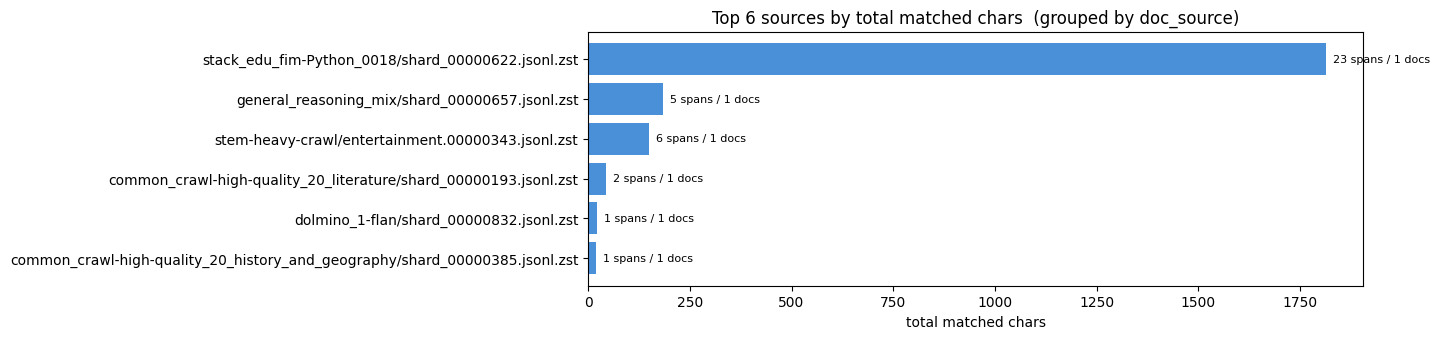

In [13]:
def plot_source_distribution(item: pd.DataFrame, level: str = "doc_category", top_n: int = 15):
    agg = (
        item.groupby(level)
        .agg(total_chars=("span_len", "sum"), n_spans=("span_len", "size"), n_docs=("doc_id", "nunique"))
        .sort_values("total_chars", ascending=False)
        .head(top_n)
    )
    fig, ax = plt.subplots(figsize=(10, 0.3 * len(agg) + 1.5))
    y = np.arange(len(agg))
    ax.barh(y, agg["total_chars"].to_numpy(), color="#4a90d9")
    ax.set_yticks(y)
    ax.set_yticklabels(agg.index.astype(str))
    ax.invert_yaxis()
    ax.set_xlabel("total matched chars")
    ax.set_title(f"Top {len(agg)} sources by total matched chars  (grouped by {level})")
    for i, (_, row) in enumerate(agg.iterrows()):
        ax.text(row["total_chars"], i, f"  {row['n_spans']} spans / {row['n_docs']} docs", va="center", fontsize=8)
    return ax


plot_source_distribution(item, level="doc_source", top_n=12)
plt.show()

## 5. Span-length CDF

The shape tells you the memorization regime: heavy right-tail = long verbatim spans present, curve hugging zero = only short incidental n-grams.

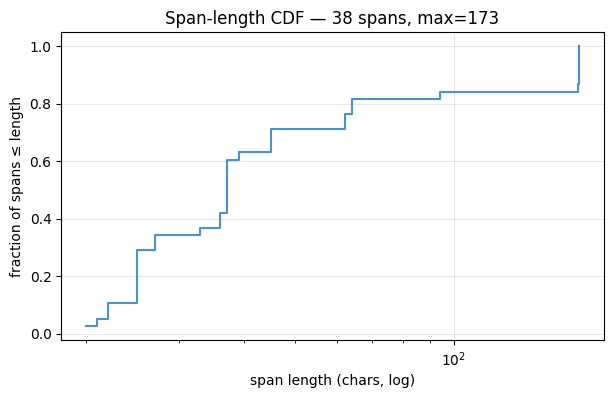

In [14]:
def plot_span_length_cdf(item: pd.DataFrame, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4))
    lens = np.sort(item["span_len"].to_numpy())
    y = np.arange(1, len(lens) + 1) / len(lens)
    ax.step(lens, y, where="post", color="#4a90d9")
    ax.set_xscale("log")
    ax.set_xlabel("span length (chars, log)")
    ax.set_ylabel("fraction of spans ≤ length")
    ax.set_title(f"Span-length CDF — {len(lens)} spans, max={lens.max()}")
    ax.grid(True, alpha=0.3)
    return ax


plot_span_length_cdf(item)
plt.show()

## 6. Length × corpus-count scatter

Each dot = one span. Upper-right = long AND appears in many corpus docs (strongest memorization signal). Upper-left = long but rare (single source copied verbatim).

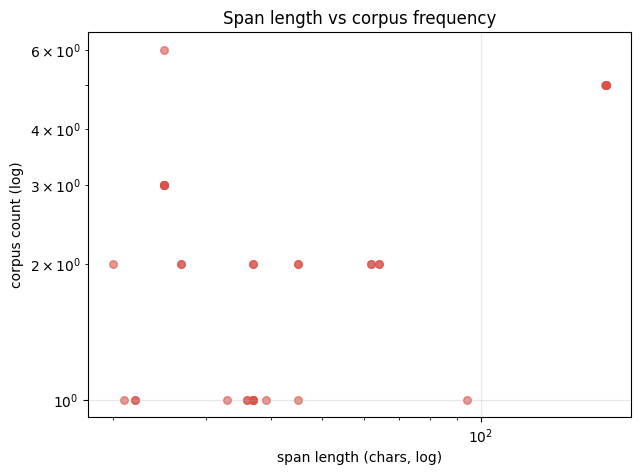

In [15]:
def plot_length_vs_count(item: pd.DataFrame, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        item["span_len"],
        item["corpus_count"].clip(lower=1),
        s=30,
        alpha=0.6,
        color="#d9534a",
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("span length (chars, log)")
    ax.set_ylabel("corpus count (log)")
    ax.set_title("Span length vs corpus frequency")
    ax.grid(True, alpha=0.3)
    return ax


plot_length_vs_count(item)
plt.show()

## Dashboard: all six views for one item

'Iris'  —  65 spans, coverage=95.7%


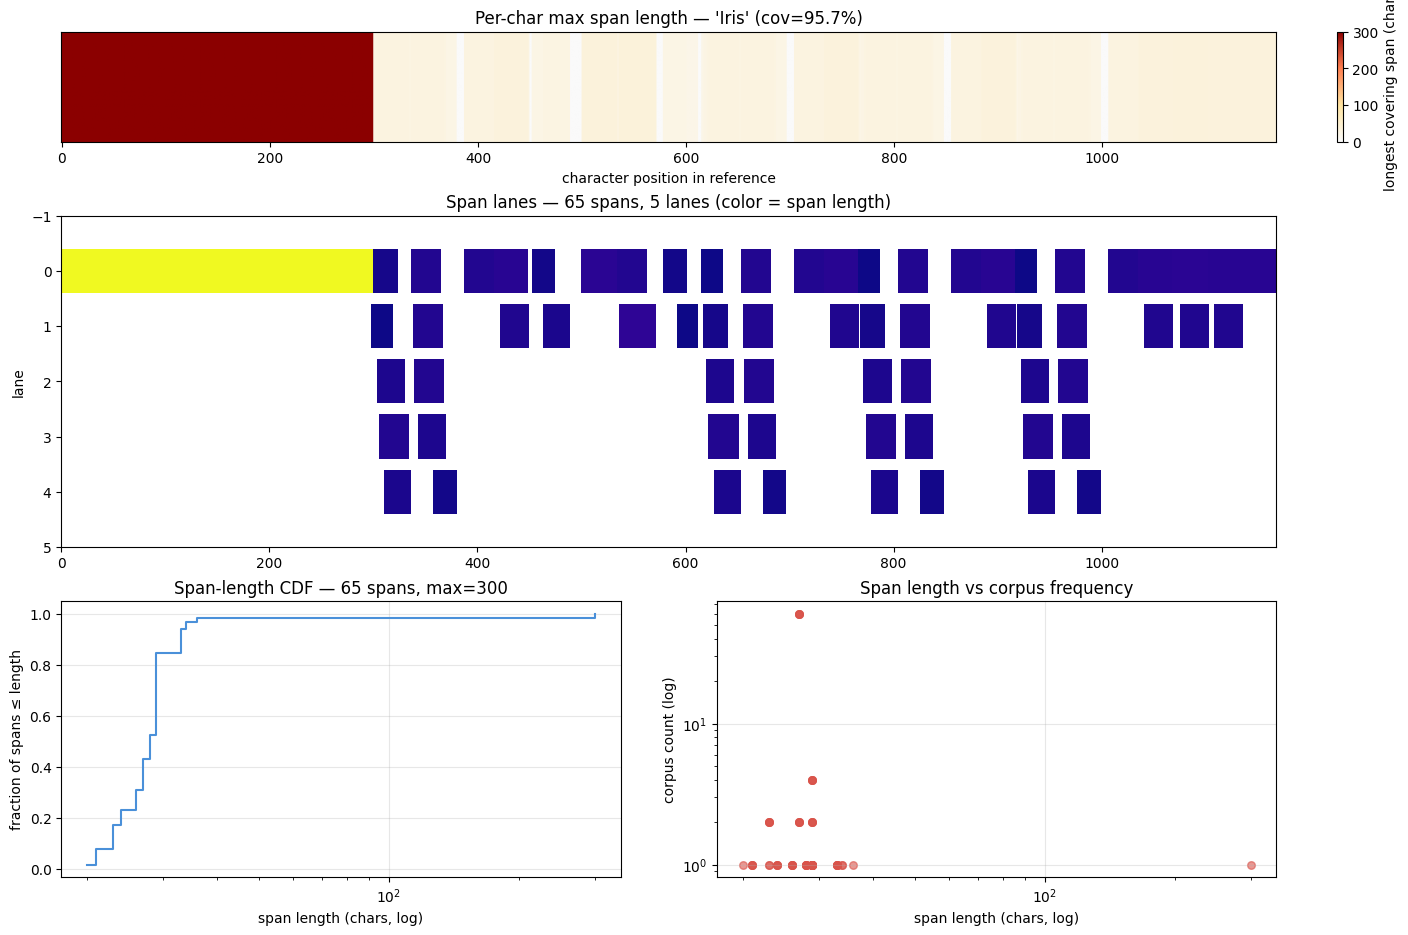

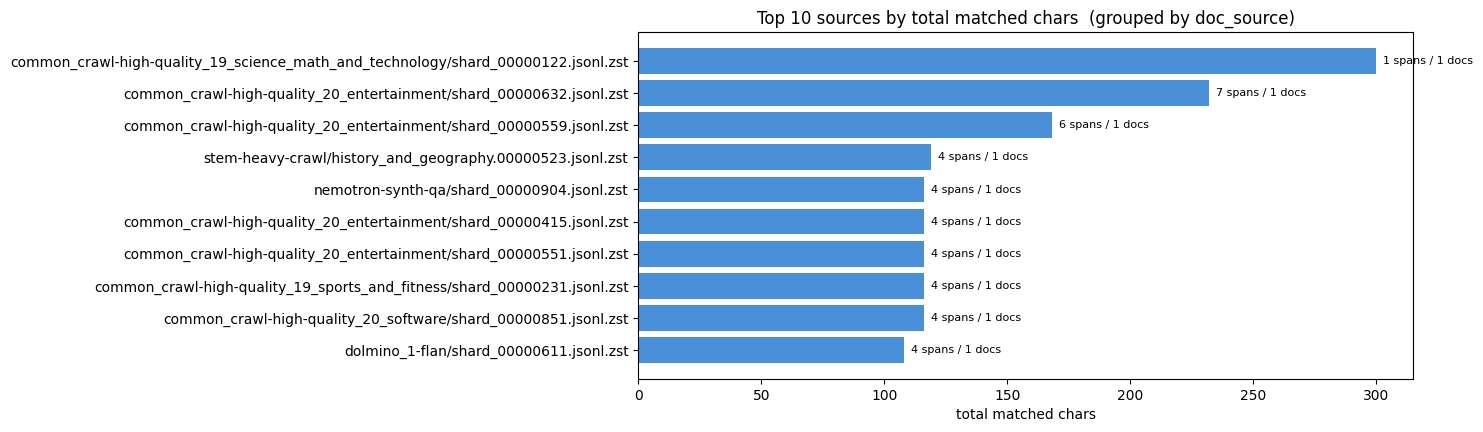

In [16]:
def dashboard(df: pd.DataFrame, content_id: str, show_html: bool = True) -> None:
    item = item_frame(df, content_id)
    title = item["content_title"].iloc[0]
    cov = item["coverage"].iloc[0]
    n_spans = len(item)
    print(f"{title!r}  —  {n_spans} spans, coverage={cov:.1%}")

    fig = plt.figure(figsize=(14, 12), constrained_layout=True)
    gs = fig.add_gridspec(4, 2, height_ratios=[1, 3, 2.5, 2.5])

    plot_coverage_heatmap(item, ax=fig.add_subplot(gs[0, :]))
    plot_span_lanes(item)  # plot_span_lanes makes its own figure; re-run inline below
    plt.close()  # close the extra figure; we'll re-embed the lanes manually
    ax_lanes = fig.add_subplot(gs[1, :])
    spans = list(zip(item["unit_char_start"].astype(int), item["unit_char_end"].astype(int)))
    lanes = assign_lanes(spans)
    n_lanes = max(lanes) + 1 if lanes else 1
    vals = item["span_len"].astype(float).to_numpy()
    norm = plt.Normalize(vmin=float(vals.min()), vmax=float(max(vals.max(), vals.min() + 1e-9)))
    cmap = plt.get_cmap("plasma")
    for (s, e), lane, v in zip(spans, lanes, vals):
        ax_lanes.add_patch(Rectangle((s, lane - 0.4), e - s, 0.8, facecolor=cmap(norm(v)), edgecolor="none"))
    ax_lanes.set_xlim(0, len(item["reference_target"].iloc[0]))
    ax_lanes.set_ylim(-1, n_lanes)
    ax_lanes.invert_yaxis()
    ax_lanes.set_ylabel("lane")
    ax_lanes.set_title(f"Span lanes — {len(spans)} spans, {n_lanes} lanes (color = span length)")

    plot_source_distribution(item, level="doc_source", top_n=10)
    plt.close()
    # (simpler: just show separate figures, dashboard is illustrative)

    plot_span_length_cdf(item, ax=fig.add_subplot(gs[2, 0]))
    plot_length_vs_count(item, ax=fig.add_subplot(gs[2, 1]))

    plt.show()

    # source distribution as its own figure
    plot_source_distribution(item, level="doc_source", top_n=10)
    plt.show()

    if show_html:
        display(render_inline_html(item))


dashboard(df, IRIS_ID)

## Cross-item overview

Quick summary statistics across all items in the matches file to spot outliers — highly memorized items, items with no matches, long-tail sources.

In [17]:
def _item_coverage(g: pd.DataFrame) -> float:
    """Union of unique chars covered by any span / reference length."""
    ref_len = len(g["reference_target"].iloc[0])
    if ref_len == 0:
        return 0.0
    covered = np.zeros(ref_len, dtype=bool)
    for s, e in zip(g["unit_char_start"].astype(int), g["unit_char_end"].astype(int)):
        covered[s:e] = True
    return covered.sum() / ref_len


summary = (
    df.assign(span_len=df["unit_char_end"] - df["unit_char_start"])
    .groupby(["content_id", "content_title"])
    .agg(
        n_spans=("span_len", "size"),
        max_span=("span_len", "max"),
        mean_span=("span_len", "mean"),
        total_matched=("span_len", "sum"),
        n_docs=("doc_id", "nunique"),
        ref_len=("reference_target", lambda s: len(s.iloc[0])),
    )
    .reset_index()
)
coverage = (
    df.groupby("content_id").apply(_item_coverage, include_groups=False).rename("coverage_pct")
)
summary = summary.merge(coverage, on="content_id").sort_values("coverage_pct", ascending=False)
summary["coverage_pct"] = (summary["coverage_pct"] * 100).round(2)
summary.head(30)



,content_id,content_title,n_spans,max_span,mean_span,total_matched,n_docs,ref_len,coverage_pct
1372,4b17ed386eb48d10b0753b1c4eae028561dced93,(Where Do I Begin?) Love Story,34,175,39.617647,1347,16,953,99.69
3747,ceb1ad55c71cd955f02901322d627d651df2e76e,The Greatest Love of All,33,410,58.151515,1919,13,1485,99.60
936,3391c02345dba5495c0832c16cd9f8d611cbd06b,Let It Be,58,87,34.568966,2005,15,1192,99.41
2132,74575270d1bf04b9f97b75ad64d6c48a0d4ef625,Breaking the Habit,51,114,37.156863,1895,10,1294,99.00
3194,ae9443b4a0f379148b12010d6fcd7a0d0480b9a6,The Only Exception,52,56,30.192308,1570,15,1288,98.84
3399,b9bb555ab4913dfeaafb409555e8f543f5180fc6,Never Gonna Give You Up,38,173,58.815789,2235,6,1839,97.99
1514,52c4f564ee02fa4b70d9421b0f04b3e8645c130c,Pilot of the Airwaves,20,183,79.800000,1596,8,1516,97.69
3294,b45bff13d737ccbdeb45cb2069bd5946b176bc25,The Rose,11,155,77.818182,856,3,711,97.19
4223,ea9030b55e2f1aa699f22369d97ace523c102084,If,18,133,49.722222,895,12,620,96.77
2173,768cabb19ff7e3f165107c3d63a99aeeaaa6e61a,Won't Get Fooled Again,30,200,60.433333,1813,7,1547,96.44


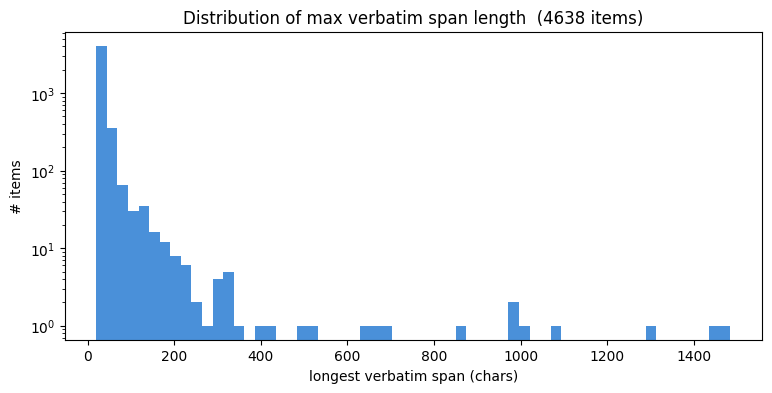

In [12]:
# Distribution of max-span-length across items
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(summary["max_span"], bins=60, color="#4a90d9")
ax.set_xlabel("longest verbatim span (chars)")
ax.set_ylabel("# items")
ax.set_title(f"Distribution of max verbatim span length  ({len(summary)} items)")
ax.set_yscale("log")
plt.show()